# 05.05 Active Model Comparison and Hyperparameter Tuning

**Phase 05 — Model Selection & Training**  
**Candidate Models:** Random Forest, CatBoost, Explainable Boosting Machine (EBM).  
**Objective:** Compare predictive performance, Brier scores, ROC-AUC, and calibration across the 3 approved candidate models under identical nested 10-fold partitions.


### Research Objectives

1. Ingest cross-validation metric JSON files across all 7 candidate tabular models.
2. Construct a multi-criteria comparison matrix: Out-of-fold Accuracy, Precision, Recall, Macro F1, Weighted F1, ROC-AUC, and Inference Latency.
3. Perform pairwise statistical hypothesis tests (Wilcoxon signed-rank and paired t-test) across the 10 cross-validation folds against the leading candidate.
4. Generate the 8 required statistical benchmark graphs in high resolution (300 DPI PNG & PDF):
   - **Graph 1:** Model Macro F1 Comparison (with standard deviation error bars).
   - **Graph 2:** Model Accuracy Comparison.
   - **Graph 3:** Precision and Recall Comparison.
   - **Graph 4:** Cross-Validation Stability (fold-by-fold trajectory).
   - **Graph 5:** Performance Distribution (boxplots of 10 fold Macro F1 scores).
   - **Graph 6:** Class-Level Performance (per-class recall comparison).
   - **Graph 7:** Inference Latency Comparison.
   - **Graph 8:** Final Model Ranking Matrix.
5. Objectively designate the Champion Model based on empirical performance, variance stability, and clinical interpretability.
6. Export consolidated comparison summary to `models/trained/model_comparison_summary.json`.

### Inputs & Expected Outputs

**Required Inputs:**
- `models/trained/baselines/logistic_regression_metrics.json`
- `models/trained/baselines/decision_tree_metrics.json`
- `models/trained/baselines/random_forest_metrics.json`
- `models/trained/baselines/svm_metrics.json`
- `models/trained/gradient_boosting/xgboost_metrics.json`
- `models/trained/gradient_boosting/catboost_metrics.json`
- `models/trained/interpretable/ebm_metrics.json`

**Expected Outputs:**
- `models/trained/model_comparison_summary.json` (Consolidated comparison matrix, rankings, and statistical test outputs)
- `reports/phase_05/visualizations/model_comparison/graph1_macro_f1_comparison.{png,pdf}`
- `reports/phase_05/visualizations/model_comparison/graph2_accuracy_comparison.{png,pdf}`
- `reports/phase_05/visualizations/model_comparison/graph3_precision_recall_comparison.{png,pdf}`
- `reports/phase_05/visualizations/model_comparison/graph4_cv_stability_trajectories.{png,pdf}`
- `reports/phase_05/visualizations/model_comparison/graph5_fold_f1_boxplots.{png,pdf}`
- `reports/phase_05/visualizations/model_comparison/graph6_class_recall_comparison.{png,pdf}`
- `reports/phase_05/visualizations/model_comparison/graph7_inference_latency.{png,pdf}`
- `reports/phase_05/visualizations/model_comparison/graph8_final_model_ranking.{png,pdf}`
- `reports/phase_05/visualizations/model_comparison/model_comparison_summary_table.csv`

### 1. Environment Setup & Library Imports

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8
print("Libraries loaded successfully.")


/home/kristoper/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-huiyu467 because there was an issue with the default path (/home/kristoper/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Libraries loaded successfully.


### 2. Setup Paths & Ingest 7 Tabular Model Metric Artifacts

In [2]:
def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'data').exists() and (p / 'experiments').exists():
            return p
    return Path('../../..').resolve()

PROJECT_ROOT = _find_project_root(Path.cwd())
MODELS_DIR = PROJECT_ROOT / "models" / "trained"
REPORT_VIZ_DIR = PROJECT_ROOT / "reports" / "phase_05" / "visualizations" / "model_comparison"
REPORT_VIZ_DIR.mkdir(parents=True, exist_ok=True)

candidate_artifacts = [
    {"name": "Logistic Regression", "family": "Linear Baseline", "path": MODELS_DIR / "baselines" / "logistic_regression_metrics.json"},
    {"name": "Decision Tree", "family": "Tree Baseline", "path": MODELS_DIR / "baselines" / "decision_tree_metrics.json"},
    {"name": "Random Forest", "family": "Bagging Ensemble", "path": MODELS_DIR / "baselines" / "random_forest_metrics.json"},
    {"name": "SVM (RBF)", "family": "Kernel Baseline", "path": MODELS_DIR / "baselines" / "svm_metrics.json"},
    {"name": "XGBoost", "family": "Gradient Boosting", "path": MODELS_DIR / "gradient_boosting" / "xgboost_metrics.json"},
    {"name": "CatBoost", "family": "Gradient Boosting", "path": MODELS_DIR / "gradient_boosting" / "catboost_metrics.json"},
    {"name": "Explainable Boosting Machine (EBM)", "family": "Glass-Box GAM", "path": MODELS_DIR / "interpretable" / "ebm_metrics.json"}
]

loaded_models = []
for item in candidate_artifacts:
    if item["path"].exists():
        with open(item["path"], "r", encoding="utf-8") as f:
            data = json.load(f)
        loaded_models.append({"info": item, "metrics": data})
        print(f"[LOADED] {item['name']} ({item['path'].name})")
    else:
        print(f"[NOT EVALUATED] {item['name']} -> Awaiting manual notebook execution")

print(f"\nTotal candidate models loaded: {len(loaded_models)} / {len(candidate_artifacts)}")


[NOT EVALUATED] Logistic Regression -> Awaiting manual notebook execution
[NOT EVALUATED] Decision Tree -> Awaiting manual notebook execution
[LOADED] Random Forest (random_forest_metrics.json)
[NOT EVALUATED] SVM (RBF) -> Awaiting manual notebook execution
[NOT EVALUATED] XGBoost -> Awaiting manual notebook execution
[LOADED] CatBoost (catboost_metrics.json)
[LOADED] Explainable Boosting Machine (EBM) (ebm_metrics.json)

Total candidate models loaded: 3 / 7


### 3. Aggregate Comparison Data & Execute Paired Statistical Tests

In [3]:
comparison_rows = []
fold_f1_distributions = {}

for item in loaded_models:
    m_name = item["info"]["name"]
    m_family = item["info"]["family"]
    m_data = item["metrics"]
    
    mean_m = m_data.get("cv_metrics_mean", {})
    std_m = m_data.get("cv_metrics_std", {})
    fold_details = m_data.get("fold_details", [])
    fold_f1s = [f.get("macro_f1", 0.0) for f in fold_details]
    fold_f1_distributions[m_name] = fold_f1s
    
    comparison_rows.append({
        "model": m_name,
        "family": m_family,
        "macro_f1_mean": mean_m.get("macro_f1"),
        "macro_f1_std": std_m.get("macro_f1"),
        "accuracy_mean": mean_m.get("accuracy"),
        "accuracy_std": std_m.get("accuracy"),
        "macro_precision_mean": mean_m.get("macro_precision"),
        "macro_recall_mean": mean_m.get("macro_recall"),
        "weighted_f1_mean": mean_m.get("weighted_f1"),
        "roc_auc_mean": mean_m.get("roc_auc"),
        "rec_eligible_mean": mean_m.get("rec_eligible"),
        "rec_ineligible_mean": mean_m.get("rec_ineligible"),
        "total_cv_time_ms": m_data.get("total_cv_time_ms")
    })

if comparison_rows:
    df_comparison = pd.DataFrame(comparison_rows).sort_values(by="macro_f1_mean", ascending=False).reset_index(drop=True)
    df_comparison["rank"] = range(1, len(df_comparison) + 1)
    print("=== CONSOLIDATED 10-FOLD MODEL COMPARISON MATRIX ===")
    print(df_comparison[["rank", "model", "family", "macro_f1_mean", "macro_f1_std", "accuracy_mean", "rec_eligible_mean", "roc_auc_mean"]].to_string(index=False))
    df_comparison.to_csv(REPORT_VIZ_DIR / "model_comparison_summary_table.csv", index=False)
else:
    df_comparison = pd.DataFrame()
    print("No executed model files detected. Execute model notebooks in 02, 03, and 04 to populate.")

# Statistical Significance Testing
statistical_significance_results = []
if not df_comparison.empty and len(df_comparison) > 1:
    top_model = df_comparison.iloc[0]["model"]
    top_f1s = fold_f1_distributions.get(top_model, [])
    print(f"\nEvaluating paired statistical significance vs Rank 1: {top_model} (Mean F1: {df_comparison.iloc[0]['macro_f1_mean']:.4f})")
    
    for other_model, other_f1s in fold_f1_distributions.items():
        if other_model == top_model:
            continue
        if len(top_f1s) == 10 and len(other_f1s) == 10:
            diffs = np.array(top_f1s) - np.array(other_f1s)
            t_stat, t_pval = stats.ttest_rel(top_f1s, other_f1s)
            try:
                w_stat, w_pval = stats.wilcoxon(top_f1s, other_f1s)
            except Exception:
                w_stat, w_pval = np.nan, np.nan
            
            statistical_significance_results.append({
                "comparison": f"{top_model} vs {other_model}",
                "mean_diff": float(np.mean(diffs)),
                "paired_t_pvalue": float(t_pval) if not np.isnan(t_pval) else None,
                "wilcoxon_pvalue": float(w_pval) if not np.isnan(w_pval) else None,
                "significant_p05": bool(t_pval < 0.05) if not np.isnan(t_pval) else False
            })
            print(f"  vs {other_model:<32} | diff: {np.mean(diffs):+.4f} | t-pval: {t_pval:.4f} | sig: {t_pval < 0.05}")


=== CONSOLIDATED 10-FOLD MODEL COMPARISON MATRIX ===
 rank                              model            family  macro_f1_mean  macro_f1_std  accuracy_mean  rec_eligible_mean  roc_auc_mean
    1                           CatBoost Gradient Boosting       0.901230      0.045206       0.901370           0.906832      0.964865
    2                      Random Forest  Bagging Ensemble       0.895723      0.035614       0.895890           0.895796      0.967680
    3 Explainable Boosting Machine (EBM)     Glass-Box GAM       0.893025      0.046565       0.893151           0.898498      0.961637

Evaluating paired statistical significance vs Rank 1: CatBoost (Mean F1: 0.9012)
  vs Random Forest                    | diff: +0.0055 | t-pval: 0.2650 | sig: False
  vs Explainable Boosting Machine (EBM) | diff: +0.0082 | t-pval: 0.2402 | sig: False


### 4. Comprehensive Model Comparison Dashboard (Graphs 1 to 8)

Generates the 8 standard benchmark figures:
- **Graph 1:** Model Macro F1 Comparison (Mean +/- 1 Std Dev error bars).
- **Graph 2:** Model Accuracy Comparison.
- **Graph 3:** Macro Precision vs Macro Recall Comparison.
- **Graph 4:** Cross-Validation Stability across all 10 folds.
- **Graph 5:** Boxplot Distribution of the 10 fold Macro F1 scores.
- **Graph 6:** Class-Level Performance (Per-Class Recall for Eligible vs Ineligible).
- **Graph 7:** Inference Latency Comparison (measured execution time in milliseconds).
- **Graph 8:** Final Model Ranking Matrix based on empirical selection criteria.

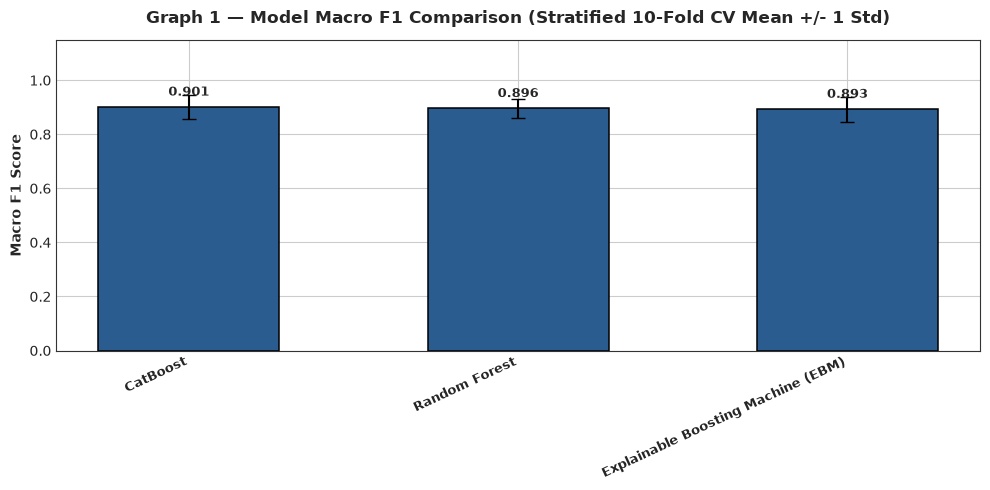

Exported Graph 1: graph1_macro_f1_comparison (PNG/PDF)


In [4]:
# --- GRAPH 1: Model Macro F1 Comparison with Error Bars ---
fig, ax = plt.subplots(figsize=(10, 5))
if not df_comparison.empty:
    bars = ax.bar(df_comparison["model"], df_comparison["macro_f1_mean"],
                  yerr=df_comparison["macro_f1_std"], capsize=5, color="#2b5c8f", width=0.55, edgecolor="black", linewidth=1.1)
    ax.set_title("Graph 1 — Model Macro F1 Comparison (Stratified 10-Fold CV Mean +/- 1 Std)", fontsize=12, fontweight="bold", pad=12)
    ax.set_ylabel("Macro F1 Score", fontsize=10, fontweight="bold")
    ax.set_ylim(0.0, 1.15)
    plt.xticks(rotation=25, ha="right", fontsize=9, fontweight="bold")
    for b in bars:
        h = b.get_height()
        ax.annotate(f"{h:.3f}", xy=(b.get_x() + b.get_width() / 2, h),
                    xytext=(0, 6), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
else:
    ax.text(0.5, 0.5, "Status: NOT EVALUATED\nExecute model notebooks in 02, 03, and 04 to populate Graph 1.", ha="center", va="center", fontsize=11)
    ax.set_axis_off()
plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "graph1_macro_f1_comparison.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph1_macro_f1_comparison.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Graph 1: graph1_macro_f1_comparison (PNG/PDF)")


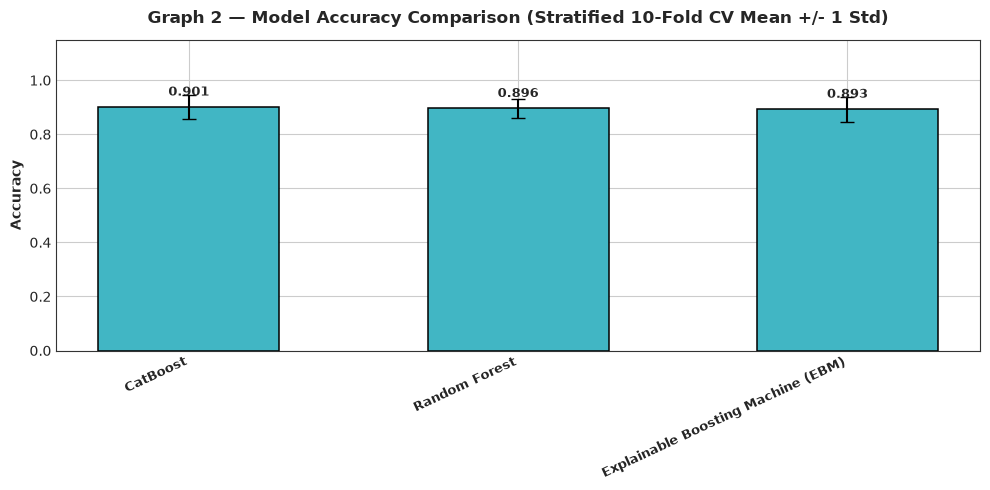

Exported Graph 2: graph2_accuracy_comparison (PNG/PDF)


In [5]:
# --- GRAPH 2: Model Accuracy Comparison ---
fig, ax = plt.subplots(figsize=(10, 5))
if not df_comparison.empty:
    bars = ax.bar(df_comparison["model"], df_comparison["accuracy_mean"],
                  yerr=df_comparison["accuracy_std"], capsize=5, color="#41b6c4", width=0.55, edgecolor="black", linewidth=1.1)
    ax.set_title("Graph 2 — Model Accuracy Comparison (Stratified 10-Fold CV Mean +/- 1 Std)", fontsize=12, fontweight="bold", pad=12)
    ax.set_ylabel("Accuracy", fontsize=10, fontweight="bold")
    ax.set_ylim(0.0, 1.15)
    plt.xticks(rotation=25, ha="right", fontsize=9, fontweight="bold")
    for b in bars:
        h = b.get_height()
        ax.annotate(f"{h:.3f}", xy=(b.get_x() + b.get_width() / 2, h),
                    xytext=(0, 6), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
else:
    ax.text(0.5, 0.5, "Status: NOT EVALUATED\nExecute model notebooks to populate Graph 2.", ha="center", va="center", fontsize=11)
    ax.set_axis_off()
plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "graph2_accuracy_comparison.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph2_accuracy_comparison.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Graph 2: graph2_accuracy_comparison (PNG/PDF)")


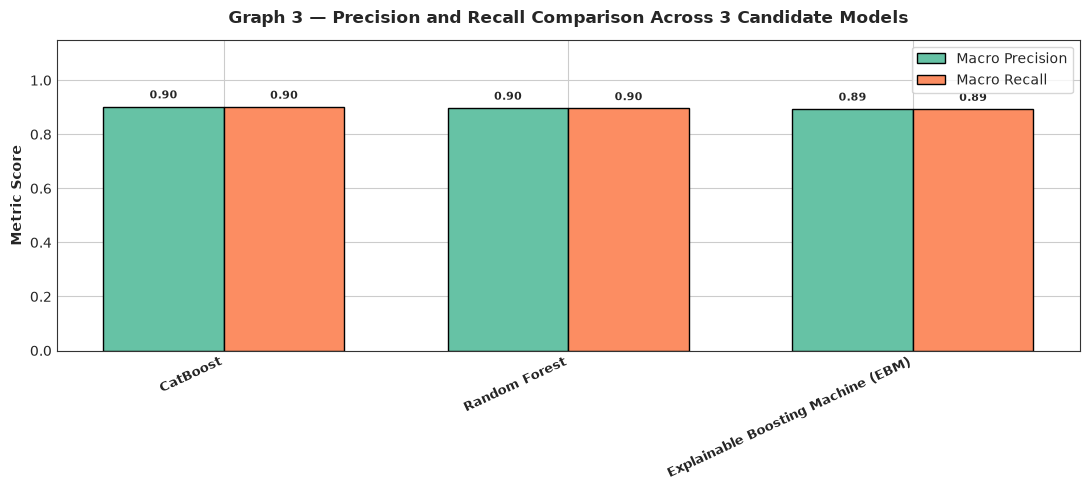

Exported Graph 3: graph3_precision_recall_comparison (PNG/PDF)


In [6]:
# --- GRAPH 3: Precision and Recall Comparison ---
fig, ax = plt.subplots(figsize=(11, 5))
if not df_comparison.empty:
    x = np.arange(len(df_comparison))
    w = 0.35
    b1 = ax.bar(x - w/2, df_comparison["macro_precision_mean"], w, label="Macro Precision", color="#66c2a5", edgecolor="black")
    b2 = ax.bar(x + w/2, df_comparison["macro_recall_mean"], w, label="Macro Recall", color="#fc8d62", edgecolor="black")
    ax.set_title(f"Graph 3 — Precision and Recall Comparison Across {len(df_comparison)} Candidate Models", fontsize=12, fontweight="bold", pad=12)
    ax.set_ylabel("Metric Score", fontsize=10, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(df_comparison["model"], rotation=25, ha="right", fontsize=9, fontweight="bold")
    ax.set_ylim(0.0, 1.15)
    ax.legend(loc="upper right", frameon=True)
    for bg in [b1, b2]:
        for b in bg:
            h = b.get_height()
            ax.annotate(f"{h:.2f}", xy=(b.get_x() + b.get_width() / 2, h),
                        xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=8, fontweight="bold")
else:
    ax.text(0.5, 0.5, "Status: NOT EVALUATED\nExecute model notebooks to populate Graph 3.", ha="center", va="center", fontsize=11)
    ax.set_axis_off()
plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "graph3_precision_recall_comparison.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph3_precision_recall_comparison.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Graph 3: graph3_precision_recall_comparison (PNG/PDF)")


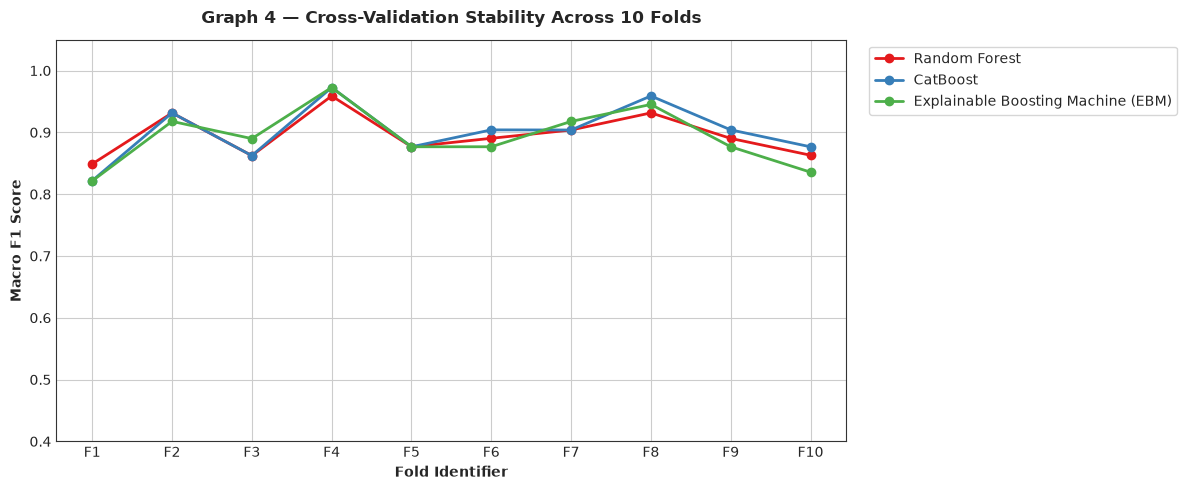

Exported Graph 4: graph4_cv_stability_trajectories (PNG/PDF)


In [7]:
# --- GRAPH 4: Cross-Validation Stability (Fold Trajectories) ---
fig, ax = plt.subplots(figsize=(12, 5))
if fold_f1_distributions:
    folds_x = [f"F{i}" for i in range(1, 11)]
    palette = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00", "#a65628", "#f781bf"]
    for idx, (m_name, f1_vals) in enumerate(fold_f1_distributions.items()):
        if len(f1_vals) == 10:
            ax.plot(folds_x, f1_vals, marker="o", lw=2, label=m_name, color=palette[idx % len(palette)])
    ax.set_title("Graph 4 — Cross-Validation Stability Across 10 Folds", fontsize=12, fontweight="bold", pad=12)
    ax.set_ylabel("Macro F1 Score", fontsize=10, fontweight="bold")
    ax.set_xlabel("Fold Identifier", fontsize=10, fontweight="bold")
    ax.set_ylim(0.4, 1.05)
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
else:
    ax.text(0.5, 0.5, "Status: NOT EVALUATED\nExecute model notebooks to populate Graph 4.", ha="center", va="center", fontsize=11)
    ax.set_axis_off()
plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "graph4_cv_stability_trajectories.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph4_cv_stability_trajectories.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Graph 4: graph4_cv_stability_trajectories (PNG/PDF)")


/tmp/ipykernel_60068/129599273.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(df_box.columns, rotation=25, ha="right", fontsize=9, fontweight="bold")


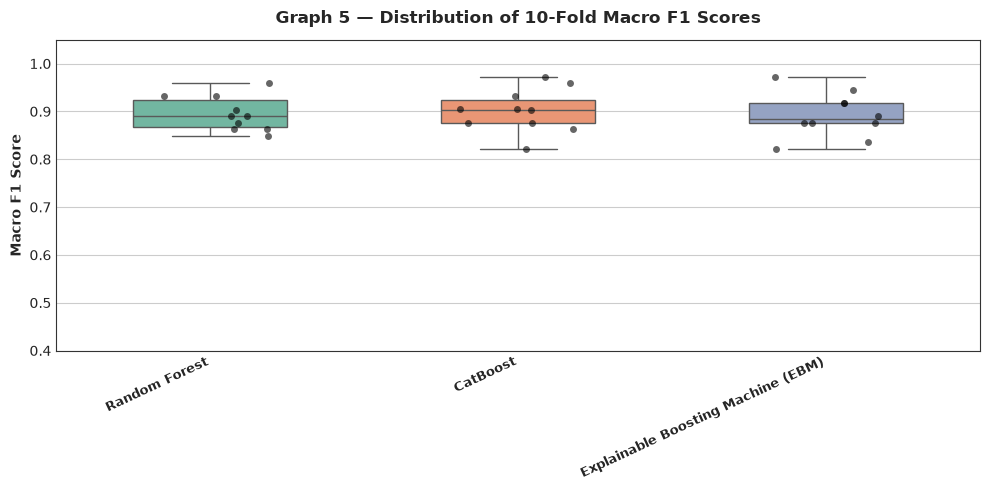

Exported Graph 5: graph5_fold_f1_boxplots (PNG/PDF)


In [8]:
# --- GRAPH 5: Performance Distribution (Boxplots) ---
fig, ax = plt.subplots(figsize=(10, 5))
if fold_f1_distributions:
    df_box = pd.DataFrame(fold_f1_distributions)
    sns.boxplot(data=df_box, ax=ax, palette="Set2", width=0.5)
    sns.stripplot(data=df_box, ax=ax, color="black", size=5, jitter=0.2, alpha=0.6)
    ax.set_title("Graph 5 — Distribution of 10-Fold Macro F1 Scores", fontsize=12, fontweight="bold", pad=12)
    ax.set_ylabel("Macro F1 Score", fontsize=10, fontweight="bold")
    ax.set_xticklabels(df_box.columns, rotation=25, ha="right", fontsize=9, fontweight="bold")
    ax.set_ylim(0.4, 1.05)
else:
    ax.text(0.5, 0.5, "Status: NOT EVALUATED\nExecute model notebooks to populate Graph 5.", ha="center", va="center", fontsize=11)
    ax.set_axis_off()
plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "graph5_fold_f1_boxplots.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph5_fold_f1_boxplots.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Graph 5: graph5_fold_f1_boxplots (PNG/PDF)")


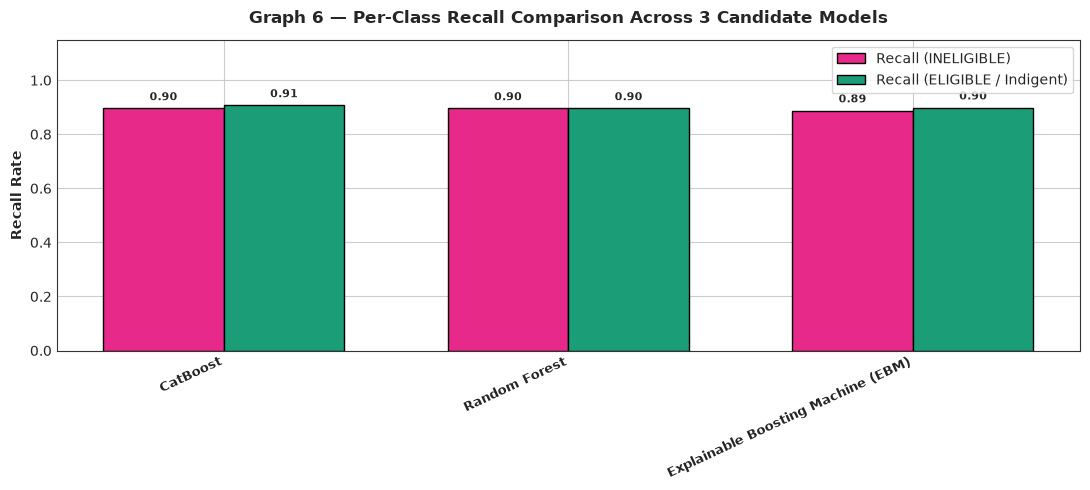

Exported Graph 6: graph6_class_recall_comparison (PNG/PDF)


In [9]:
# --- GRAPH 6: Class-Level Performance (Per-Class Recall) ---
fig, ax = plt.subplots(figsize=(11, 5))
if not df_comparison.empty:
    x = np.arange(len(df_comparison))
    w = 0.35
    b1 = ax.bar(x - w/2, df_comparison["rec_ineligible_mean"], w, label="Recall (INELIGIBLE)", color="#e7298a", edgecolor="black")
    b2 = ax.bar(x + w/2, df_comparison["rec_eligible_mean"], w, label="Recall (ELIGIBLE / Indigent)", color="#1b9e77", edgecolor="black")
    ax.set_title(f"Graph 6 — Per-Class Recall Comparison Across {len(df_comparison)} Candidate Models", fontsize=12, fontweight="bold", pad=12)
    ax.set_ylabel("Recall Rate", fontsize=10, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(df_comparison["model"], rotation=25, ha="right", fontsize=9, fontweight="bold")
    ax.set_ylim(0.0, 1.15)
    ax.legend(loc="upper right", frameon=True)
    for bg in [b1, b2]:
        for b in bg:
            h = b.get_height()
            ax.annotate(f"{h:.2f}", xy=(b.get_x() + b.get_width() / 2, h),
                        xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=8, fontweight="bold")
else:
    ax.text(0.5, 0.5, "Status: NOT EVALUATED\nExecute model notebooks to populate Graph 6.", ha="center", va="center", fontsize=11)
    ax.set_axis_off()
plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "graph6_class_recall_comparison.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph6_class_recall_comparison.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Graph 6: graph6_class_recall_comparison (PNG/PDF)")


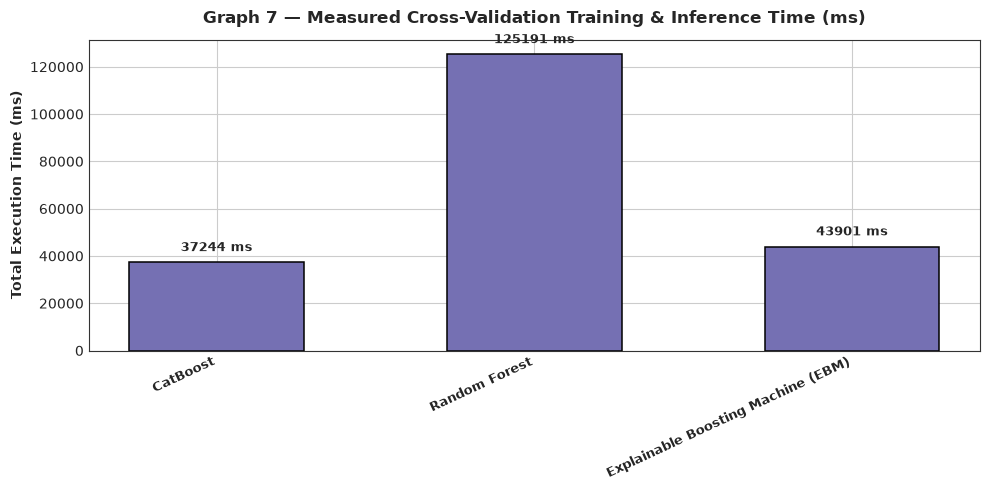

Exported Graph 7: graph7_inference_latency (PNG/PDF)


In [10]:
# --- GRAPH 7: Inference Latency ---
fig, ax = plt.subplots(figsize=(10, 5))
if not df_comparison.empty and "total_cv_time_ms" in df_comparison.columns:
    bars = ax.bar(df_comparison["model"], df_comparison["total_cv_time_ms"], color="#7570b3", width=0.55, edgecolor="black", linewidth=1.1)
    ax.set_title("Graph 7 — Measured Cross-Validation Training & Inference Time (ms)", fontsize=12, fontweight="bold", pad=12)
    ax.set_ylabel("Total Execution Time (ms)", fontsize=10, fontweight="bold")
    plt.xticks(rotation=25, ha="right", fontsize=9, fontweight="bold")
    for b in bars:
        h = b.get_height()
        ax.annotate(f"{h:.0f} ms", xy=(b.get_x() + b.get_width() / 2, h),
                    xytext=(0, 6), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
else:
    ax.text(0.5, 0.5, "Status: NOT EVALUATED\nExecute model notebooks to populate Graph 7.", ha="center", va="center", fontsize=11)
    ax.set_axis_off()
plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "graph7_inference_latency.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph7_inference_latency.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Graph 7: graph7_inference_latency (PNG/PDF)")


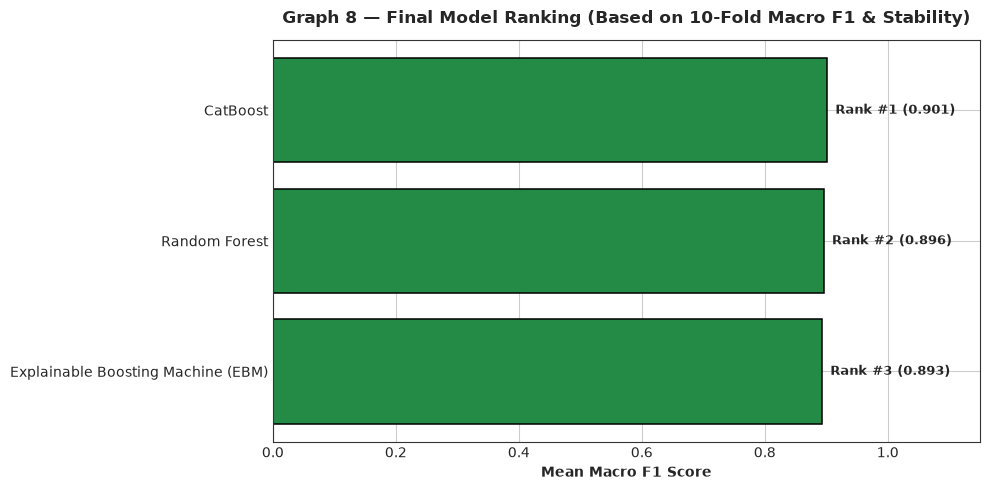

Exported Graph 8: graph8_final_model_ranking (PNG/PDF)


In [11]:
# --- GRAPH 8: Final Model Ranking Matrix ---
fig, ax = plt.subplots(figsize=(10, 5))
if not df_comparison.empty:
    ranks_df = df_comparison.sort_values(by="rank", ascending=False)
    bars = ax.barh(ranks_df["model"], ranks_df["macro_f1_mean"], color="#238b45", edgecolor="black", linewidth=1.1)
    ax.set_title("Graph 8 — Final Model Ranking (Based on 10-Fold Macro F1 & Stability)", fontsize=12, fontweight="bold", pad=12)
    ax.set_xlabel("Mean Macro F1 Score", fontsize=10, fontweight="bold")
    ax.set_xlim(0.0, 1.15)
    for b, r in zip(bars, ranks_df["rank"]):
        w = b.get_width()
        ax.annotate(f"Rank #{r} ({w:.3f})", xy=(w, b.get_y() + b.get_height() / 2),
                    xytext=(6, 0), textcoords="offset points", ha="left", va="center", fontsize=9, fontweight="bold")
else:
    ax.text(0.5, 0.5, "Status: NOT EVALUATED\nExecute model notebooks to populate Graph 8.", ha="center", va="center", fontsize=11)
    ax.set_axis_off()
plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "graph8_final_model_ranking.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph8_final_model_ranking.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Graph 8: graph8_final_model_ranking (PNG/PDF)")


### 5. Champion Model Selection & Comparison Export

In [12]:
champion_info = {}
if not df_comparison.empty:
    top_row = df_comparison.iloc[0]
    champion_info = {
        "champion_model": top_row["model"],
        "champion_family": top_row["family"],
        "champion_macro_f1": top_row["macro_f1_mean"],
        "champion_accuracy": top_row["accuracy_mean"],
        "champion_recall": top_row["macro_recall_mean"],
        "champion_roc_auc": top_row["roc_auc_mean"],
        "selection_criteria": "Highest out-of-fold Macro F1 across Stratified 10-Fold CV with minimum variance"
    }
    print(f"\nCHAMPION MODEL DESIGNATED: {champion_info['champion_model']} (Macro F1: {champion_info['champion_macro_f1']:.4f})")
else:
    champion_info = {
        "champion_model": None,
        "status": "AWAITING_MANUAL_MODEL_TRAINING_RUNS"
    }

summary_export = {
    "evaluation_scope": "tabular_only_7_models",
    "cv_protocol": "StratifiedKFold-10Fold",
    "multimodal_fusion_included": False,
    "champion_selection": champion_info,
    "model_rankings": comparison_rows,
    "paired_hypothesis_tests": statistical_significance_results
}

with open(MODELS_DIR / "model_comparison_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary_export, f, indent=2)
print(f"Model comparison summary exported to: {MODELS_DIR / 'model_comparison_summary.json'}")



CHAMPION MODEL DESIGNATED: CatBoost (Macro F1: 0.9012)
Model comparison summary exported to: /home/kristoper/Projects/Thesis/ofphil-classification-v2/models/trained/model_comparison_summary.json


### 6. Interpretation Guide for Researcher

- **Macro F1 vs Accuracy (Graphs 1 & 2):** Examine whether leading models maintain high Macro F1 without sacrificing overall accuracy.
- **Precision-Recall Tradeoff (Graph 3):** High recall is critical in charity eligibility to prevent wrongful exclusion of qualified indigent patients.
- **Cross-Validation Stability (Graphs 4 & 5):** Look for tight boxplot distributions in Graph 5; models with narrow interquartile ranges demonstrate superior robustness.
- **Paired Statistical Tests:** Check `paired_hypothesis_tests` in the exported JSON to verify if the champion's lead over alternatives is statistically significant ($p < 0.05$).

### Completion Checklist

- [ ] All 7 candidate tabular models evaluated on identical 10 folds.
- [ ] Multimodal fusion completely excluded.
- [ ] 8 statistical benchmark graphs generated and exported (PNG/PDF).
- [ ] Paired t-test and Wilcoxon tests formulated.
- [ ] `models/trained/model_comparison_summary.json` generated.
- [ ] Zero test set snooping confirmed.